### Importing all the files from S1 to S13 into a single DF:

In [1]:
from pathlib import Path
import pandas as pd

# Folder with the CSV files (raw string so the backslashes are read correctly)
data_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\MQ3_logs_S1-S13")

frames = []
skipped = []

for f in sorted(data_dir.glob("*.csv")):   # only files in this folder, not subfolders
    # Split into at most 5 parts, so yt_ext stays intact even if it contains "_"
    parts = f.stem.split("_", 4)
    if len(parts) != 5:
        skipped.append(f.name)
        continue

    set_id, vd_id, init_soc, user_state, yt_ext = parts

    df = pd.read_csv(f)              # e.g. for filename "S12_V2_95_SQ_G-XZhKqQAHU" 
    df["set_id"] = set_id            # e.g. "S12"
    df["vd_id"] = vd_id              # e.g. "V2"
    df["init_soc"] = int(init_soc)   # e.g. 95 (as a number)
    df["user_state"] = user_state    # e.g. "SQ"
    df["yt_ext"] = yt_ext            # e.g. "G-XZhKqQAHU"
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

print(f"Loaded {len(frames)} files, {len(df_all)} rows, {df_all.shape[1]} columns")
if skipped:
    print("Skipped (unexpected file name):", skipped)

df_all.head()

Loaded 70 files, 21707 rows, 46 columns


,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source,set_id,vd_id,init_soc,user_state,yt_ext
0,30,2026-10-13 18:31:42,29.61,99,4215,32.0,4953606,1701.79,7173.04,74.763,...,Running,1,0.3,00:00,manual clock,S10,V1,100,ST,KGerjHMa90s
1,31,2026-10-13 18:31:43,30.62,99,4215,32.0,4953606,1701.79,7173.04,77.731,...,Running,1,1.3,00:01,manual clock,S10,V1,100,ST,KGerjHMa90s
2,32,2026-10-13 18:31:45,32.11,99,4215,32.0,4953606,1701.79,7173.04,79.405,...,Running,1,2.8,00:02,manual clock,S10,V1,100,ST,KGerjHMa90s
3,33,2026-10-13 18:31:46,32.95,99,4215,32.0,4953606,1701.79,7173.04,81.617,...,Running,1,3.6,00:03,manual clock,S10,V1,100,ST,KGerjHMa90s
4,34,2026-10-13 18:31:47,34.06,99,4215,32.0,4953606,1701.79,7173.04,83.091,...,Running,1,4.7,00:04,manual clock,S10,V1,100,ST,KGerjHMa90s


### Checking the data is OK...How many Sets? Unique Videos?

In [2]:
meta_cols = ["set_id", "vd_id", "init_soc", "user_state", "yt_ext"]

for col in meta_cols:
    values = df_all[col].unique()
    # Sort set_id / vd_id by their number (S2 before S10), others normally
    if col in ("set_id", "vd_id"):
        values = sorted(values, key=lambda v: int(v[1:]))
    else:
        values = sorted(values)
    print(f"{col} ({len(values)} unique): {list(values)}\n")

set_id (13 unique): ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13']

vd_id (6 unique): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6']

init_soc (7 unique): [np.int64(50), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(95), np.int64(100)]

user_state (3 unique): ['DY', 'SQ', 'ST']

yt_ext (6 unique): ['G-XZhKqQAHU', 'HI7mTIxNotQ', 'KGerjHMa90s', 'Zgaw2eNP9eo', 'dwHBpykTloY', 'nF8UTFHpmjE']



### Listing all the expriments (Sets/Videos)

In [3]:
meta_cols = ["set_id", "vd_id", "init_soc", "user_state", "yt_ext"]

def to_mmss(seconds):
    """Convert seconds to an 'mm:ss' string (rounded to the nearest second)."""
    if pd.isna(seconds):
        return None
    total = int(round(seconds))
    minutes, secs = divmod(total, 60)
    return f"{minutes:02d}:{secs:02d}"

combos = (
    df_all.groupby(meta_cols)["Video Position (s)"]
          .max()
          .reset_index(name="length (s)")
)

combos["length (mm:ss)"] = combos["length (s)"].apply(to_mmss)
combos = combos.drop(columns="length (s)")

# Sort numerically by set and video (S2 before S10, V2 before V10)
combos = combos.sort_values(
    by=["set_id", "vd_id"],
    key=lambda s: s.str[1:].astype(int)
).reset_index(drop=True)

print(f"Unique combinations: {len(combos)}")
combos

Unique combinations: 70


,set_id,vd_id,init_soc,user_state,yt_ext,length (mm:ss)
0,S1,V1,100,ST,KGerjHMa90s,06:50
1,S1,V2,100,ST,G-XZhKqQAHU,04:54
2,S1,V3,100,ST,nF8UTFHpmjE,06:41
3,S1,V4,100,ST,Zgaw2eNP9eo,03:36
4,S1,V5,100,ST,HI7mTIxNotQ,06:14
...,...,...,...,...,...,...
65,S13,V2,50,ST,G-XZhKqQAHU,04:56
66,S13,V3,50,ST,nF8UTFHpmjE,06:40
67,S13,V4,50,ST,Zgaw2eNP9eo,03:38
68,S13,V5,50,ST,HI7mTIxNotQ,06:13


# ANALYSIS AND RESULTS:

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### ------------------------ 100% & Dynamic

In [5]:
def to_mmss(seconds):
    """Convert seconds to an 'mm:ss' string (rounded to the nearest second)."""
    if pd.isna(seconds):
        return None
    total = int(round(seconds))
    minutes, secs = divmod(total, 60)
    return f"{minutes:02d}:{secs:02d}"

subset = df_all[(df_all["user_state"] == "DY") & (df_all["init_soc"] == 100)]

summary = (
    subset.groupby(["set_id", "vd_id"])
          .agg(
              total_length=("Video Position (s)", "max"),
              power_max=("Accumulated Power (mWh)", "max"),
              power_min=("Accumulated Power (mWh)", "min"),
              power_first=("Accumulated Power (mWh)", "first"),
              power_last=("Accumulated Power (mWh)", "last"),
          )
          .reset_index()
)

summary["total_consumption (mWh)"] = summary["power_max"] - summary["power_min"]

# Sanity check: max - min should equal last - first if power only accumulates
last_minus_first = summary["power_last"] - summary["power_first"]
mismatch = summary[~np.isclose(summary["total_consumption (mWh)"], last_minus_first)]
if len(mismatch):
    print("Warning: max-min differs from last-first for:")
    print(mismatch[["set_id", "vd_id"]])

# Consumption per second, using the length in seconds (zero length -> NaN)
summary["consumption_rate (mWh/s)"] = (
    summary["total_consumption (mWh)"] / summary["total_length"].replace(0, np.nan)
)

# Convert length from seconds to mm:ss
summary["total_length (mm:ss)"] = summary["total_length"].apply(to_mmss)

# Keep only the requested columns, sorted numerically (S2 before S10)
summary = summary[[
    "set_id", "vd_id",
    "total_length (mm:ss)",
    "total_consumption (mWh)",
    "consumption_rate (mWh/s)",
]]
summary = summary.sort_values(
    by=["set_id", "vd_id"],
    key=lambda s: s.str[1:].astype(int)
).reset_index(drop=True)

print(f"{len(summary)} videos with user_state = ST and init_soc = 50")
summary["consumption_rate (mWh/s)"] = summary["consumption_rate (mWh/s)"].round(2)
summary

12 videos with user_state = ST and init_soc = 50


,set_id,vd_id,total_length (mm:ss),total_consumption (mWh),consumption_rate (mWh/s)
0,S3,V1,06:10,896.845,2.43
1,S3,V2,04:54,757.282,2.57
2,S3,V3,06:40,1188.415,2.97
3,S3,V4,03:38,574.177,2.64
4,S3,V5,06:14,856.097,2.29
5,S3,V6,04:35,603.309,2.19
6,S7,V1,06:12,950.761,2.55
7,S7,V2,04:53,592.398,2.02
8,S7,V3,06:45,1030.470,2.54
9,S7,V4,03:37,498.625,2.30


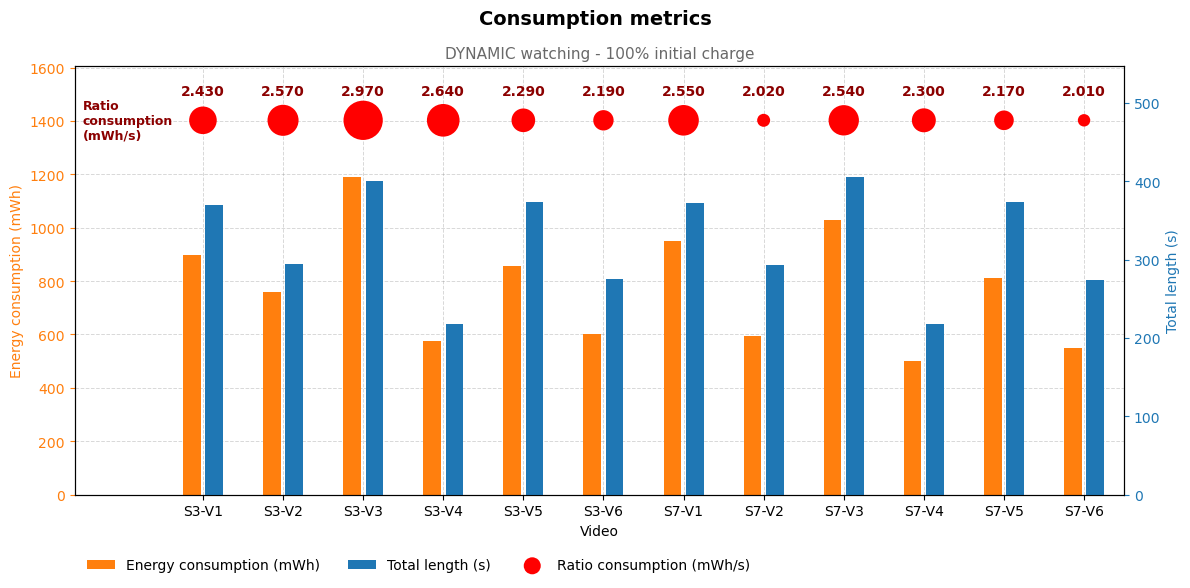

In [9]:
# Length in seconds for each video (summary only has the mm:ss text)
length_s = (
    subset.groupby(["set_id", "vd_id"])["Video Position (s)"]
          .max()
          .rename("total_length (s)")
          .reset_index()
)
plot_df = summary.merge(length_s, on=["set_id", "vd_id"])

labels = plot_df["set_id"] + "-" + plot_df["vd_id"]   # e.g. "S2-V1"
x = np.arange(len(plot_df))

width = 0.22   # thinner bars
gap = 0.06     # space between orange and blue bars
offset = width / 2 + gap / 2

cons = plot_df["total_consumption (mWh)"]
length = plot_df["total_length (s)"]
ratio = plot_df["consumption_rate (mWh/s)"]

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()   # second y-axis on the right

# Gray grid behind the bars
ax1.set_axisbelow(True)
ax1.grid(True, color="gray", alpha=0.3, linestyle="--", linewidth=0.7)

bars1 = ax1.bar(x - offset, cons, width,
                color="tab:orange", label="Energy consumption (mWh)")
bars2 = ax2.bar(x + offset, length, width,
                color="tab:blue", label="Total length (s)")

# Leave free space at the top of both axes for the circles
headroom = 1.35
ax1.set_ylim(0, cons.max() * headroom)
ax2.set_ylim(0, length.max() * headroom)

# Circle size scaled linearly with the ratio (smallest -> min_size, largest -> max_size)
min_size, max_size = 80, 800
r_min, r_max = ratio.min(), ratio.max()
if r_max > r_min:
    sizes = min_size + (ratio - r_min) / (r_max - r_min) * (max_size - min_size)
else:
    sizes = np.full(len(ratio), (min_size + max_size) / 2)

# Solid red circles, no outline
circle_y = cons.max() * 1.18
circles = ax1.scatter(x, np.full(len(x), circle_y), s=sizes, color="red",
                      edgecolors="none", zorder=3,
                      label="Ratio consumption (mWh/s)")

# Ratio value above each circle, bold and larger
for xi, r in zip(x, ratio):
    ax1.annotate(f"{r:.3f}", (xi, circle_y), xytext=(0, 18),
                 textcoords="offset points", ha="center",
                 fontsize=10, fontweight="bold", color="darkred")

# "Ratio consumption" label at the start of the circle row
ax1.set_xlim(-1.6, len(x) - 0.5)
ax1.text(-1.5, circle_y, "Ratio\nconsumption\n(mWh/s)", ha="left", va="center",
         fontsize=9, fontweight="bold", color="darkred")

# Axes labels, colored to match their bars
ax1.set_xlabel("Video")
ax1.set_ylabel("Energy consumption (mWh)", color="tab:orange")
ax2.set_ylabel("Total length (s)", color="tab:blue")
ax1.tick_params(axis="y", colors="tab:orange")
ax2.tick_params(axis="y", colors="tab:blue")

ax1.set_xticks(x)
ax1.set_xticklabels(labels)

# One legend for everything (circle in legend shown at a medium size)
leg = ax1.legend(handles=[bars1, bars2, circles], loc="upper left",
                 bbox_to_anchor=(0, -0.12), ncol=3, frameon=False)
leg.legend_handles[2].set_sizes([150])

fig.suptitle("Consumption metrics", fontsize=14, fontweight="bold")
ax1.set_title("DYNAMIC watching - 100% initial charge", fontsize=11, color="dimgray")
fig.tight_layout()

out_dir = Path(r"C:\Users\user\_MQ3_Research\Metrics\plots")
out_dir.mkdir(parents=True, exist_ok=True)   # creates the folder if needed
fig.savefig(out_dir / f"Consumption_metrics_DY_100.png", dpi=300, bbox_inches="tight")

plt.show()